# Часть 1 из 8. Загрузка данных и разведочный анализ

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- загрузка `secondary_market.csv` (вторичка) и `new_builds.csv` (новостройки), сравнение их колонок;
- сводка по типам, пропускам и уникальным значениям, описательная статистика;
- распределения числовых и дискретных признаков, матрица корреляций Пирсона.

**Графики для отчёта:**
- рисунок 1 — распределения числовых признаков (среднее и медиана в заголовках): [`figures/fig_01_numeric_distributions.png`](figures/fig_01_numeric_distributions.png)
- рисунок 2 — распределения дискретных и категориальных признаков: [`figures/fig_02_categorical_distributions.png`](figures/fig_02_categorical_distributions.png)
- рисунок 3 — матрица корреляций Пирсона для числовых признаков: [`figures/fig_03_pearson_correlation.png`](figures/fig_03_pearson_correlation.png)

[Все части](README.md) · [Часть 2. Подготовка признаков и нормализация](02_features.ipynb) →

# Предобработка

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [14]:
df_sec_m = pd.read_csv("../Moscow_Real_Estate/secondary_market.csv", na_values=[
    'NaN', 'nan', 'N/A', 'n/a', 'NA', 'null', 'NULL', 'None',
    '-', '--', '?', '', ' ', 'нет данных', 'не указано',
    '-999', '-9999', '999999', 'unknown'])

In [15]:
df_sec_m.shape

(50000, 26)

In [16]:
df_sec_m.columns.tolist()

['id',
 'date_posted',
 'district',
 'okrug',
 'lat',
 'lon',
 'total_area',
 'living_area',
 'kitchen_area',
 'rooms',
 'floor',
 'total_floors',
 'building_year',
 'building_type',
 'ceiling_height',
 'has_balcony',
 'renovation',
 'metro_station',
 'metro_line',
 'metro_distance_min',
 'metro_distance_type',
 'to_center_km',
 'price_rub',
 'price_per_sqm',
 'mortgage_rate_at_listing',
 'seller_type']

In [17]:
df_sec_m.head()

,id,date_posted,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,...,renovation,metro_station,metro_line,metro_distance_min,metro_distance_type,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing,seller_type
0,S000001,2024-11-23,Begovoy,SAO,55.79533,37.55519,71.0,46.5,6.1,2,...,cosmetic,Sokol,Zamoskvoretskaya,18,transport,6.17,15739000,221700,23.5,agency
1,S000002,2025-08-13,Sokolniki,VAO,55.79695,37.68875,79.6,52.8,10.8,3,...,no_renovation,Sokolniki,Sokolnicheskaya,7,walk,6.40,19685000,247300,19.5,owner
2,S000003,2022-05-06,Sosenskoye,NAO,55.54901,37.43118,74.0,42.2,8.9,2,...,cosmetic,Polyanka,Serpukhovsko-Timiryazevskaya,102,transport,25.70,8621000,116400,12.0,owner
3,S000004,2025-04-08,Sviblovo,SVAO,55.86462,37.61471,52.3,34.0,6.0,1,...,euro,Sviblovo,Kaluzhsko-Rizhskaya,9,walk,12.32,14771000,282400,23.5,agency
4,S000005,2023-07-16,Begovoy,SAO,55.79429,37.54631,62.2,38.3,13.1,2,...,cosmetic,Sapyornoye Pole,Bolshaya Koltsevaya,10,walk,6.47,18683000,300300,15.5,agency


In [18]:
df_new_b = pd.read_csv("../Moscow_Real_Estate/new_builds.csv", na_values=[
    'NaN', 'nan', 'N/A', 'n/a', 'NA', 'null', 'NULL', 'None',
    '-', '--', '?', '', ' ', 'нет данных', 'не указано',
    '-999', '-9999', '999999', 'unknown'])

In [19]:
df_new_b.shape

(8000, 25)

In [20]:
df_new_b.columns.to_list()

['id',
 'date_posted',
 'complex_id',
 'complex_name',
 'developer',
 'complex_class',
 'district',
 'okrug',
 'lat',
 'lon',
 'total_area',
 'rooms',
 'floor',
 'total_floors',
 'completion_year',
 'ready_status',
 'metro_station',
 'metro_line',
 'metro_distance_min',
 'to_center_km',
 'price_rub',
 'price_per_sqm',
 'deal_type',
 'subsidized_mortgage',
 'mortgage_rate_at_listing']

In [21]:
df_new_b.head()

,id,date_posted,complex_id,complex_name,developer,complex_class,district,okrug,lat,lon,...,ready_status,metro_station,metro_line,metro_distance_min,to_center_km,price_rub,price_per_sqm,deal_type,subsidized_mortgage,mortgage_rate_at_listing
0,N000001,2023-11-22,NB0250,Level Residence,PIK,business,Sosenskoye,NAO,55.56126,37.42837,...,under_construction,Kutuzovskaya,Filyovskaya,251,24.59,22075000,247200,DDU,True,15.5
1,N000002,2021-07-08,NB0015,Sheremetyevsky Residence,LSR,business,Novo-Peredelkino,ZAO,55.65817,37.32272,...,under_construction,Polyanka,Serpukhovsko-Timiryazevskaya,251,21.50,22445000,295700,DDU,True,11.0
2,N000003,2022-02-20,NB0170,Sheremetyevsky Residence,Etalon,economy,Brateyevo,YuAO,55.63503,37.73292,...,under_construction,Mayakovskaya,Zamoskvoretskaya,208,14.97,7075000,145600,DDU,True,22.5
3,N000004,2025-03-23,NB0230,Sheremetyevsky Residence,Capital Group,comfort,Voronovskoye,TAO,55.28977,37.20171,...,under_construction,Krasnopresnenskaya,Koltsevaya,695,57.96,3011000,82500,installment,False,23.5
4,N000005,2022-08-05,NB0177,Prokshino Residence,GK A101,comfort,Krasnopakhorskoye,TAO,55.43499,37.31218,...,under_construction,Yugo-Zapadnaya,Sokolnicheskaya,338,40.42,4420000,84700,DDU,True,12.0


In [22]:
cols1 = set(df_sec_m.columns)
cols2 = set(df_new_b.columns)

print("Только в df_sec_m:", cols1 - cols2)
print("Только в df_new_b:", cols2 - cols1)
print("Общие столбцы:", cols1 & cols2)

Только в df_sec_m: {'renovation', 'has_balcony', 'building_type', 'kitchen_area', 'building_year', 'seller_type', 'ceiling_height', 'living_area', 'metro_distance_type'}
Только в df_new_b: {'ready_status', 'deal_type', 'subsidized_mortgage', 'complex_name', 'complex_id', 'completion_year', 'complex_class', 'developer'}
Общие столбцы: {'metro_line', 'lon', 'date_posted', 'okrug', 'mortgage_rate_at_listing', 'price_per_sqm', 'lat', 'floor', 'id', 'total_area', 'metro_station', 'district', 'total_floors', 'rooms', 'to_center_km', 'price_rub', 'metro_distance_min'}


In [23]:
summary = pd.DataFrame({
    'dtype': df_sec_m.dtypes,
    'non_null': df_sec_m.notna().sum(),
    'null': df_sec_m.isna().sum(),
    'null_%': (df_sec_m.isna().mean() * 100).round(2),
    'unique': df_sec_m.nunique(),
    'example': [df_sec_m[c].dropna().iloc[0] if df_sec_m[c].notna().any() else None for c in df_sec_m.columns],
})
summary

,dtype,non_null,null,null_%,unique,example
id,object,50000,0,0.0,50000,S000001
date_posted,object,50000,0,0.0,2311,2024-11-23
district,object,50000,0,0.0,129,Begovoy
okrug,object,50000,0,0.0,11,SAO
lat,float64,50000,0,0.0,30403,55.79533
lon,float64,50000,0,0.0,33092,37.55519
total_area,float64,50000,0,0.0,1029,71.0
living_area,float64,50000,0,0.0,702,46.5
kitchen_area,float64,50000,0,0.0,170,6.1
rooms,int64,50000,0,0.0,5,2


In [24]:
df_sec_m.describe()

,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,metro_distance_min,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.000000
mean,55.712683,37.543657,67.053158,41.883782,11.244650,2.134900,7.475420,14.00086,1988.22008,2.787734,57.063900,16.326353,1.312282e+07,1.956257e+05,14.478795
std,0.143998,0.180338,17.309579,11.209233,2.855538,1.023153,5.530469,6.53193,23.57096,0.220836,54.483163,12.737610,8.564073e+06,1.132709e+05,5.702273
min,55.234080,36.699230,20.900000,12.600000,6.000000,1.000000,1.000000,5.00000,1935.00000,2.500000,2.000000,0.070000,1.019000e+06,2.340000e+04,6.750000
25%,55.635415,37.467110,54.400000,33.700000,9.200000,1.000000,3.000000,9.00000,1968.00000,2.700000,22.000000,9.027500,7.481750e+06,1.230000e+05,10.000000
50%,55.740110,37.565840,65.100000,40.600000,11.100000,2.000000,6.000000,12.00000,1989.00000,2.700000,39.000000,13.230000,1.108600e+07,1.704000e+05,12.000000
75%,55.817490,37.652020,77.500000,48.500000,13.100000,3.000000,10.000000,22.00000,2009.00000,3.000000,71.000000,18.060000,1.638725e+07,2.395000e+05,19.500000
max,56.020470,37.919860,134.300000,89.200000,24.800000,5.000000,25.000000,25.00000,2024.00000,3.500000,328.000000,70.550000,9.343700e+07,1.239100e+06,23.500000


In [25]:
# Числовые признаки (без target и без date)
numeric_cols = ["price_rub", "price_per_sqm", "total_area", "living_area", "kitchen_area",
                "lat", "lon", "building_year", "metro_distance_min", "to_center_km"]

# дискретные
cat_cols = ["rooms", "district", "okrug", "building_type", "has_balcony", "floor", 
            "total_floors", "metro_station", "metro_line", "metro_distance_type", "seller_type", "ceiling_height", "mortgage_rate_at_listing"]

In [26]:
import matplotlib.ticker as mticker

In [27]:
def fmt(x, _):
    if abs(x) >= 1_000_000:
        return f"{x/1_000_000:.2f}M"
    if abs(x) >= 1_000:
        return f"{x/1_000:.2f}k"
    return f"{x:.2f}"

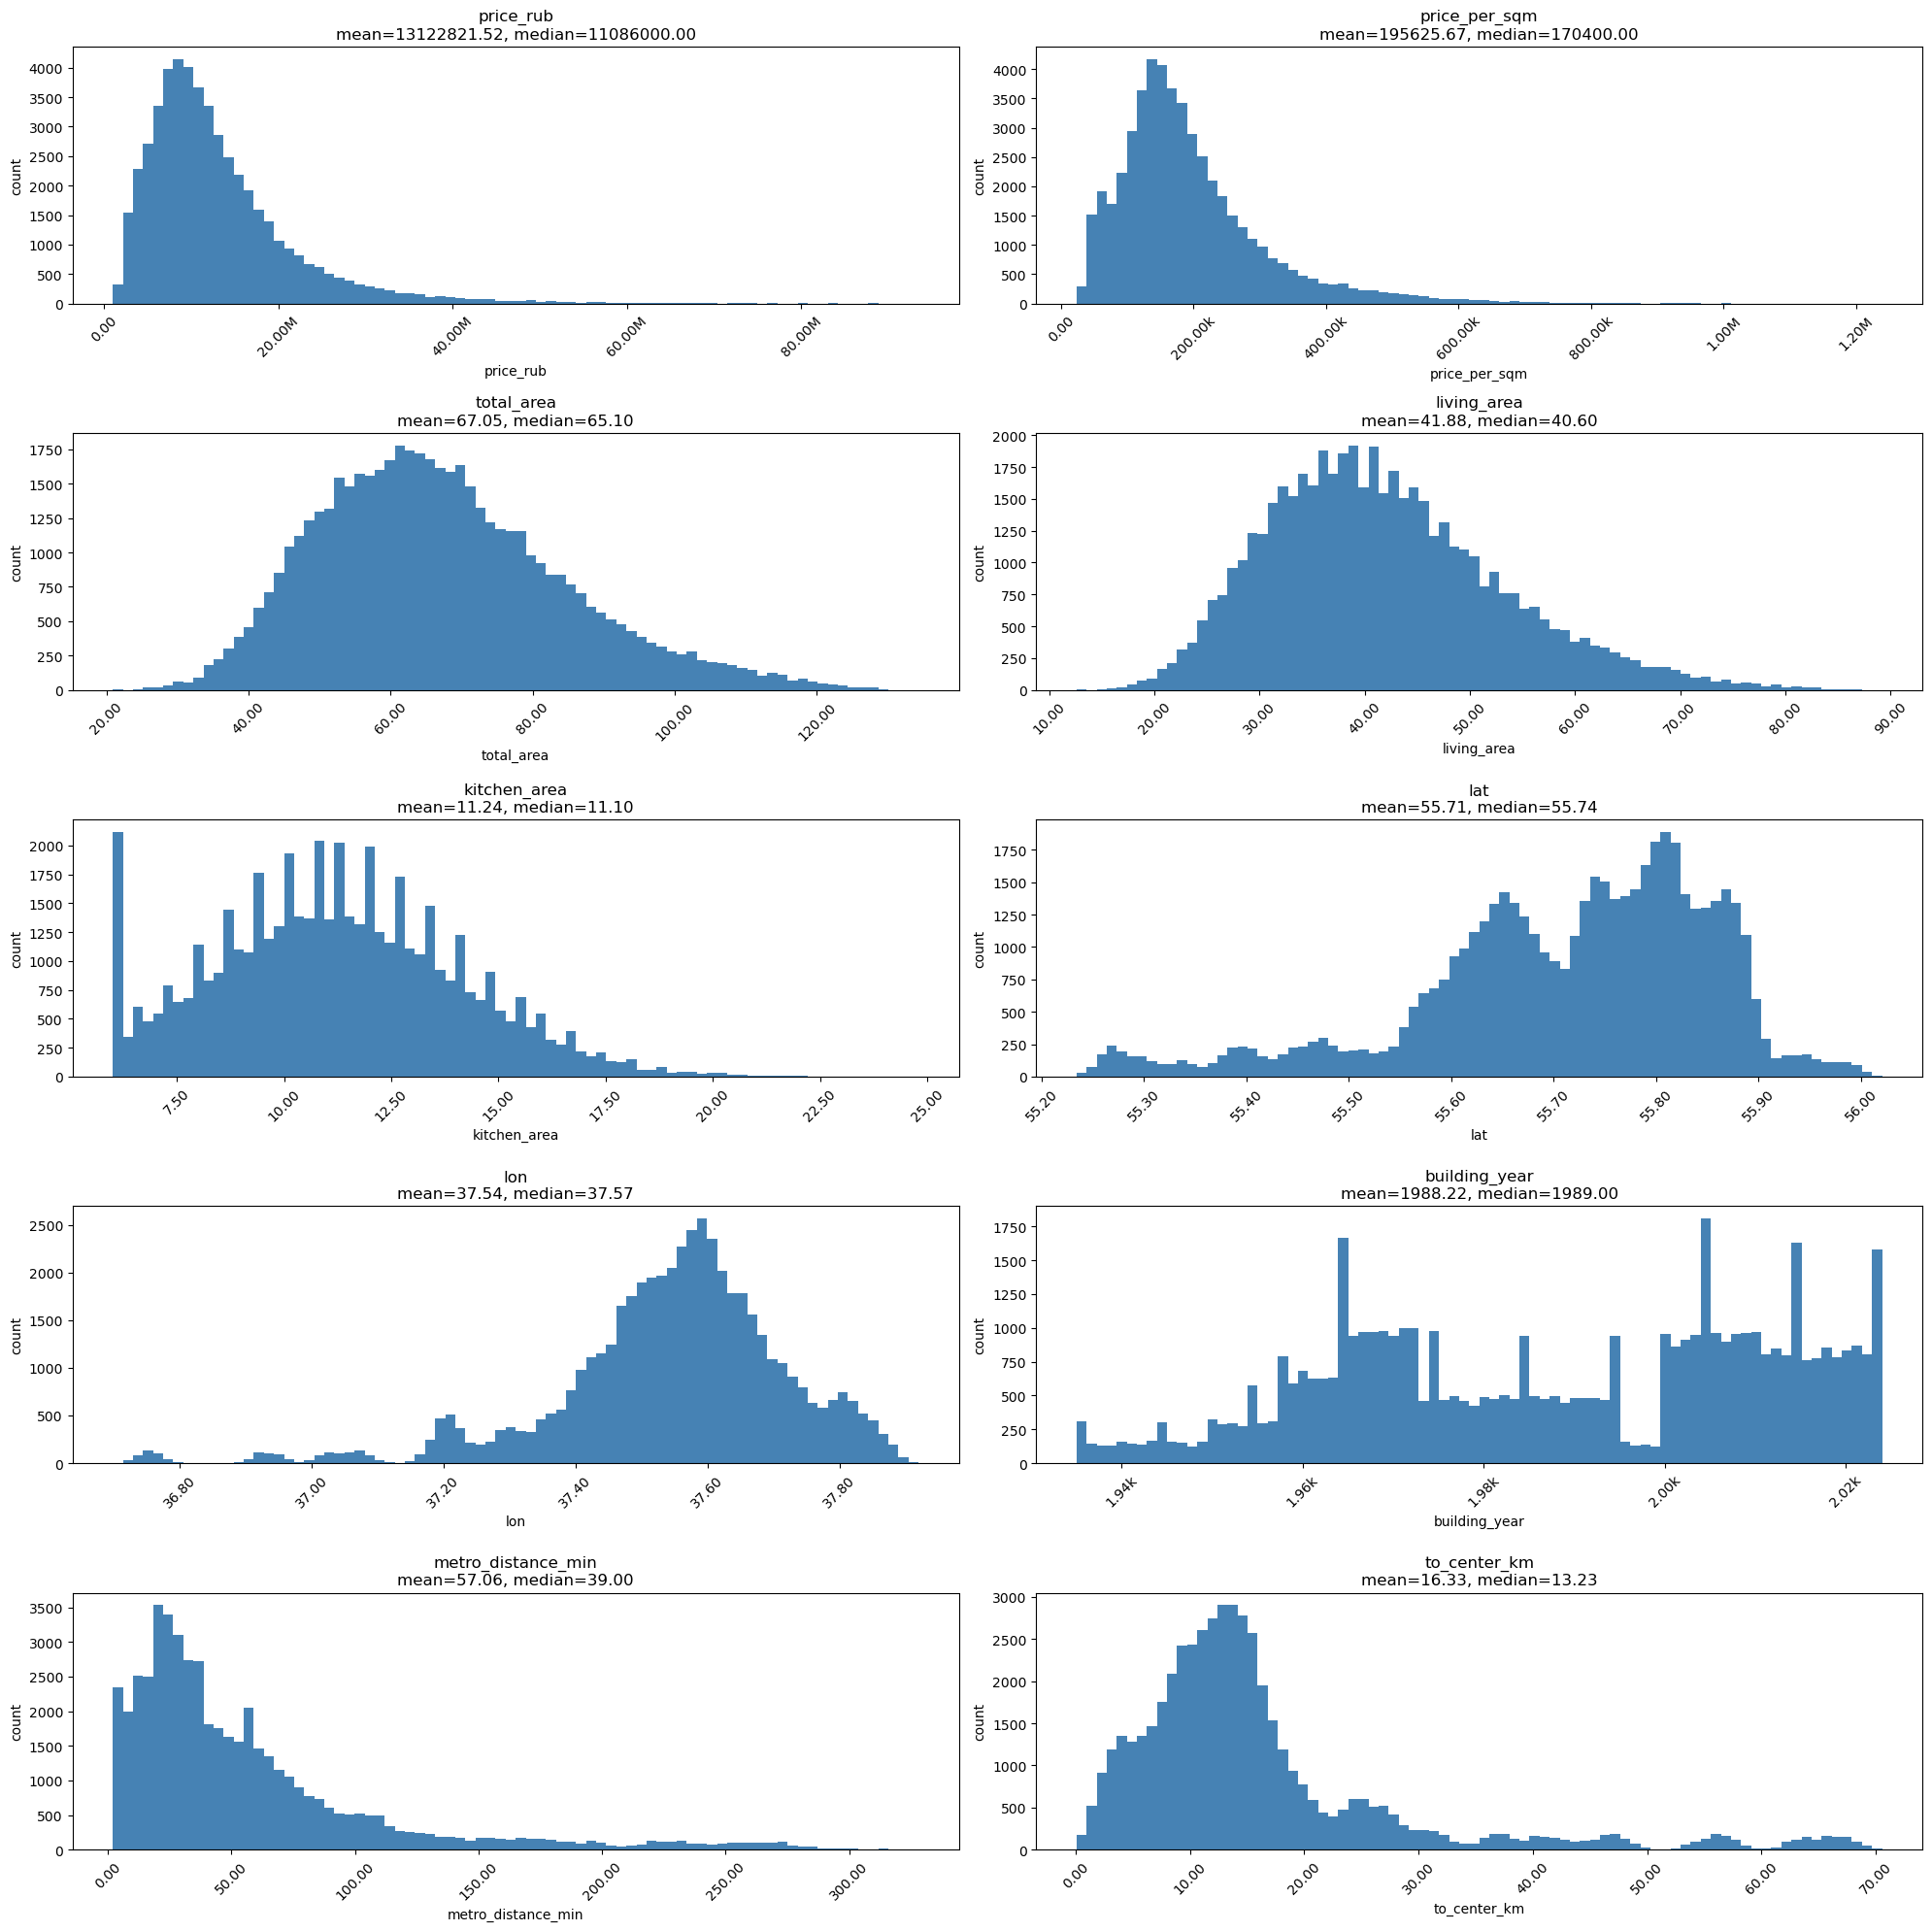

In [28]:
fig, axes = plt.subplots(5, 2, figsize=(20, 20))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df_sec_m[col].dropna(), bins=80, color="steelblue", edgecolor="none")
    axes[i].set_title(f"{col}\nmean={df_sec_m[col].mean():.2f}, median={df_sec_m[col].median():.2f}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("count")

    # Убираем 1e+6 и делаем красивые числа
    axes[i].ticklabel_format(style='plain', axis='x')
    axes[i].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
    axes[i].tick_params(axis='x', rotation=45)


# Убираем пустые оси
for j in range(len(numeric_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

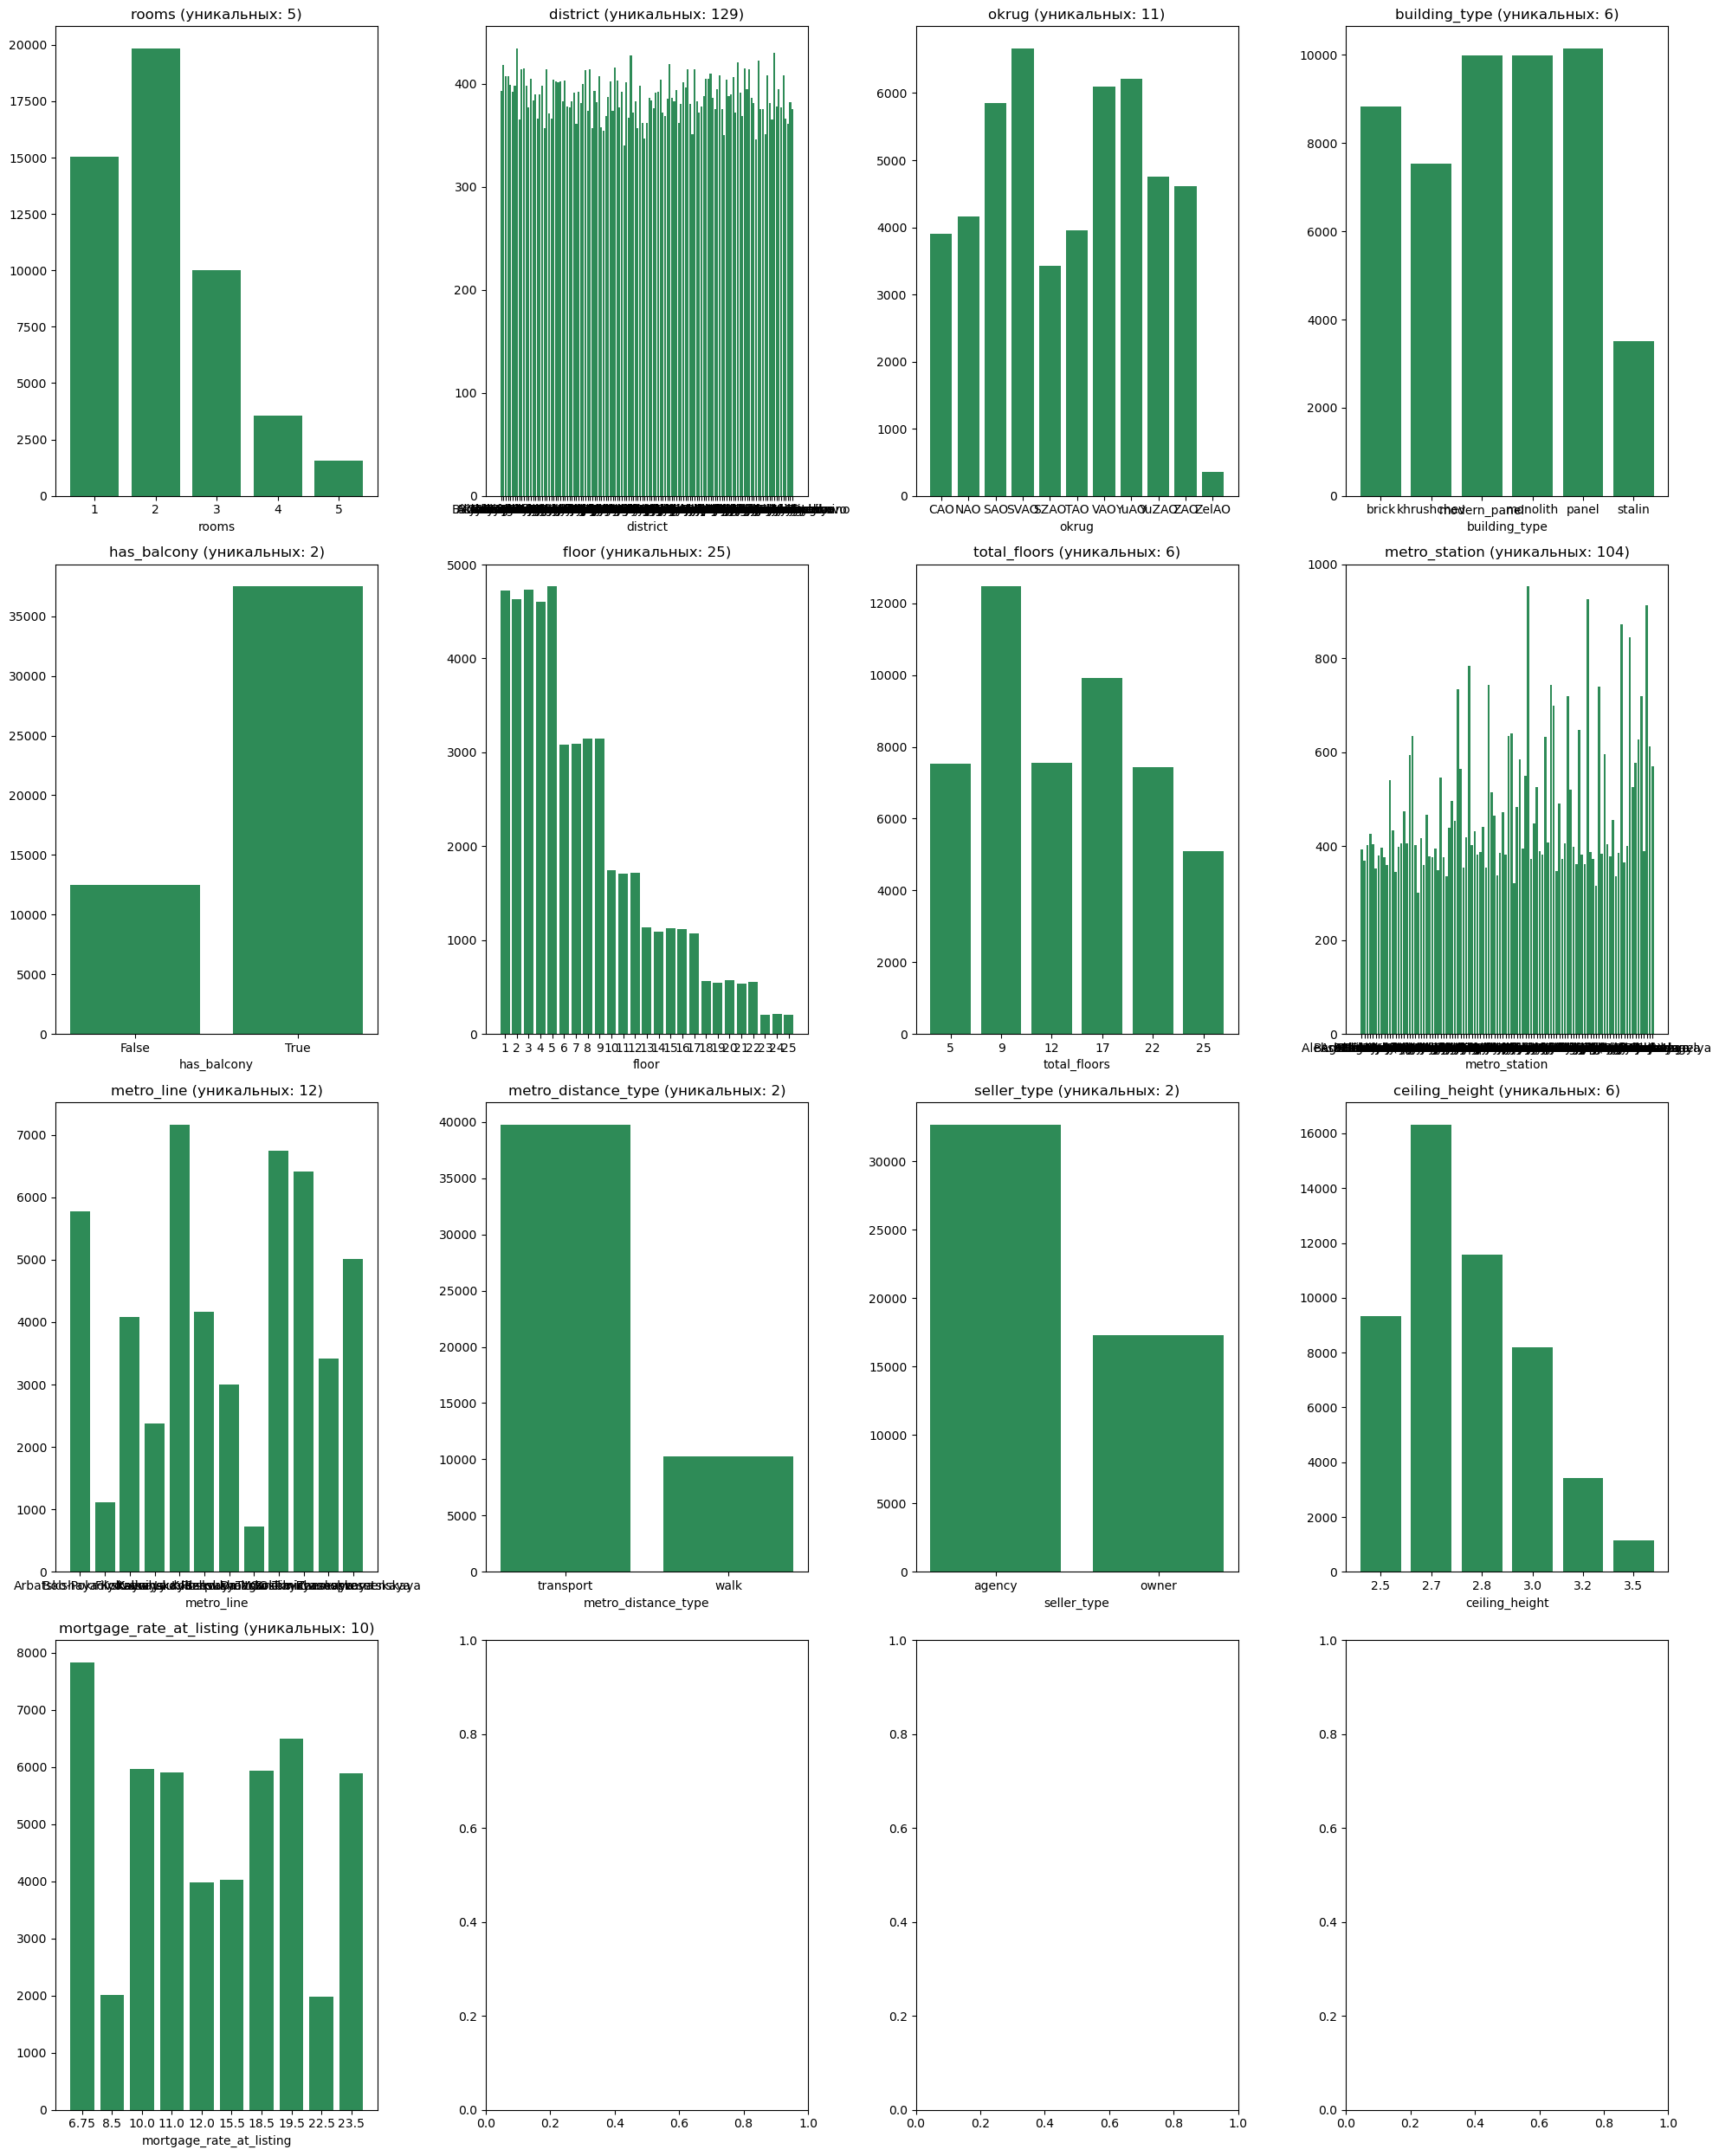

In [29]:
fig, axes = plt.subplots(4, 4, figsize=(20, 25))

for ax, col in zip(axes.ravel(), cat_cols):
    vc = df_sec_m[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="seagreen")
    ax.set_title(f"{col} (уникальных: {df_sec_m[col].nunique()})")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=90 if col == "id_region" else 0)
    if col == "id_region":
        ax.set_xticks(ax.get_xticks()[::5])   # прореживаем подписи

plt.tight_layout()
plt.show()

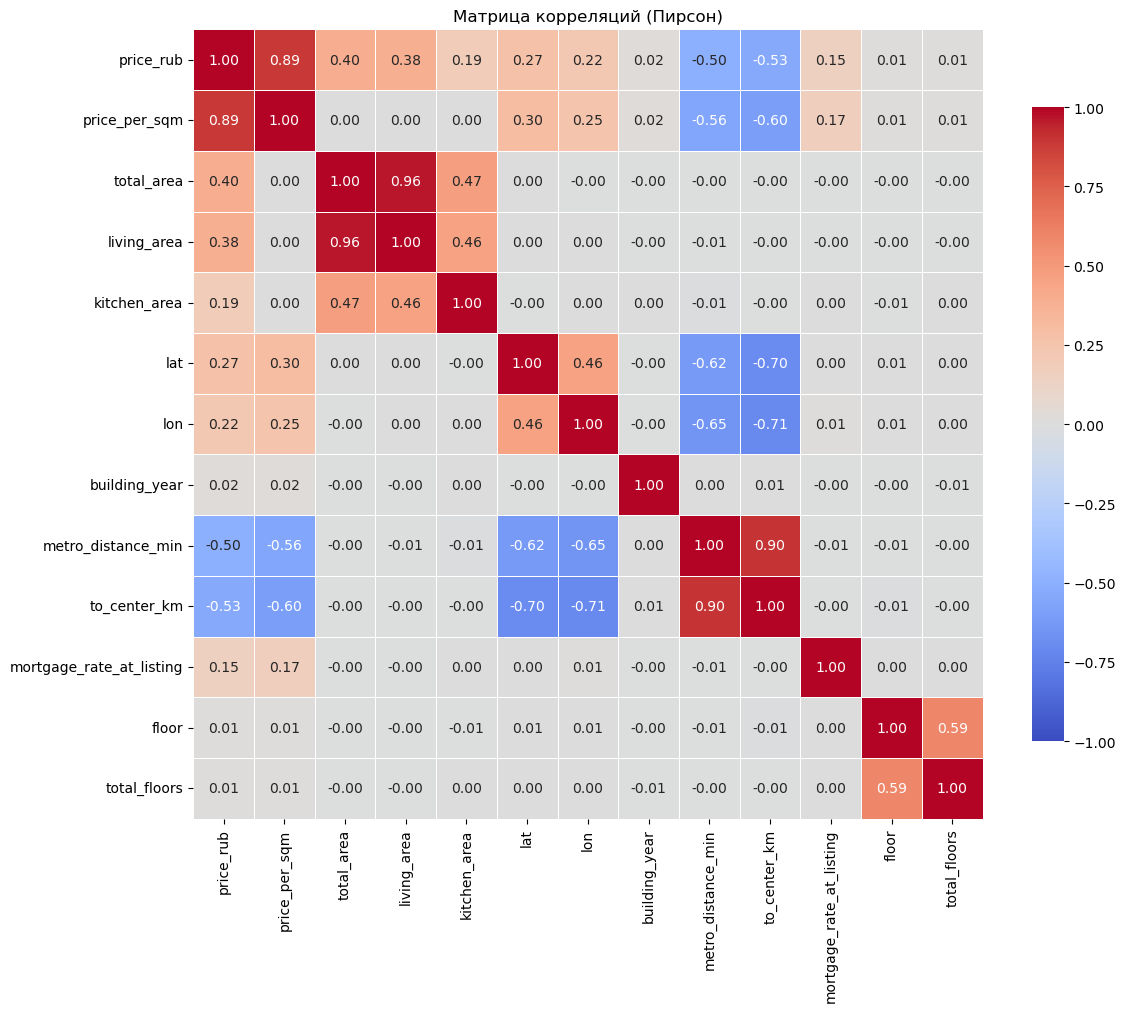

In [30]:
import seaborn as sns
# Только числовые признаки + price
corr_cols = ["price_rub", "price_per_sqm", "total_area", "living_area", "kitchen_area",
                "lat", "lon", "building_year", "metro_distance_min", "to_center_km", "mortgage_rate_at_listing", "floor", 
            "total_floors"]

corr = df_sec_m[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Матрица корреляций (Пирсон)")
plt.tight_layout()
plt.show()

---
[Все части](README.md) · [Часть 2. Подготовка признаков и нормализация](02_features.ipynb) →